In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def ruido_sal_pimienta(img, prob=0.02):
    if isinstance(img, str):
        img = cv2.imread(img, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError("No se pudo leer la imagen. Verifica la ruta o formato.")

    salida = np.copy(img)
    filas, columnas = img.shape
    ruido = np.random.rand(filas, columnas)

    salida[ruido < (prob / 2)] = 0
   
    salida[ruido > 1 - (prob / 2)] = 255

    return salida

def filtro(img, cf):
    if isinstance(img, str):
        img = cv2.imread(img, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise ValueError("No se pudo leer la imagen")

    filas, columnas = img.shape

    m, n = cf.shape
    oF = m // 2
    oC = n // 2

    suma_cf = np.sum(cf)
    if suma_cf != 0:
        cf = cf / suma_cf

    salida = np.zeros_like(img, dtype=float)

    for i in range(oF, filas - oF):
        for j in range(oC, columnas - oC):
            region = img[i - oF:i + oF + 1, j - oC:j + oC + 1]
            salida[i, j] = np.sum(region * cf)

    salida = np.clip(salida, 0, 255).astype(np.uint8)

    return salida


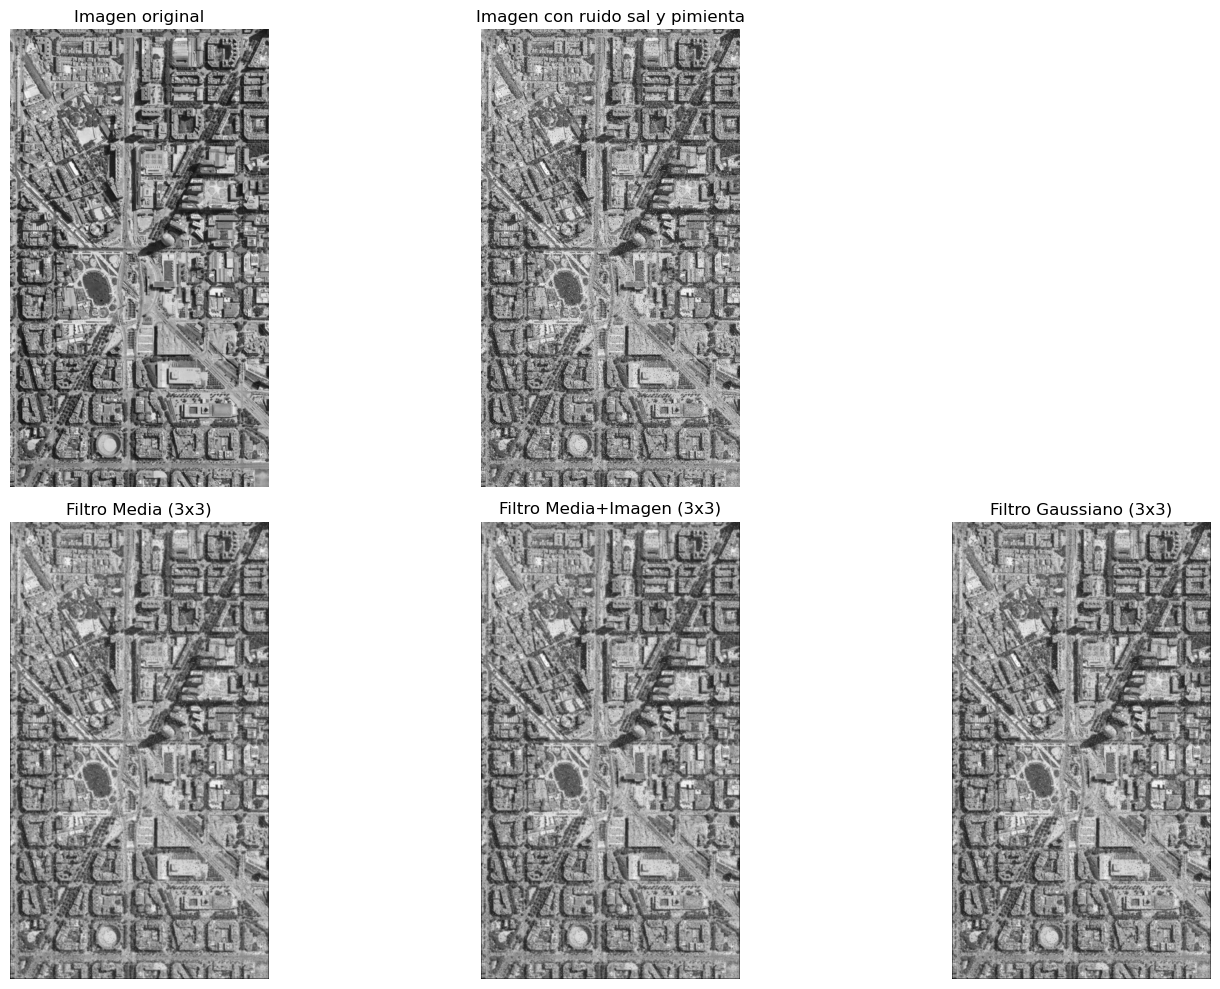

In [9]:
img = cv2.imread("Barcelona.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise ValueError("No se pudo leer la imagen. Verifica la ruta.")

img_ruido = ruido_sal_pimienta(img, prob=0.05)

filtro_media = np.array([[1, 1, 1],
                         [1, 1, 1],
                         [1, 1, 1]], dtype=float)

filtro_media_img = np.array([[1, 1, 1],
                             [1, 2, 1],
                             [1, 1, 1]], dtype=float)

filtro_gauss = np.array([[1, 2, 1],
                         [2, 4, 2],
                         [1, 2, 1]], dtype=float)

img_media = filtro(img_ruido, filtro_media)
img_media_img = filtro(img_ruido, filtro_media_img)
img_gauss = filtro(img_ruido, filtro_gauss)

# Resultados
plt.figure(figsize=(15,10))

plt.subplot(2,3,1)
plt.imshow(img, cmap='gray')
plt.title("Imagen original")
plt.axis('off')

plt.subplot(2,3,2)
plt.imshow(img_ruido, cmap='gray')
plt.title("Imagen con ruido sal y pimienta")
plt.axis('off')

plt.subplot(2,3,4)
plt.imshow(img_media, cmap='gray')
plt.title("Filtro Media (3x3)")
plt.axis('off')

plt.subplot(2,3,5)
plt.imshow(img_media_img, cmap='gray')
plt.title("Filtro Media+Imagen (3x3)")
plt.axis('off')

plt.subplot(2,3,6)
plt.imshow(img_gauss, cmap='gray')
plt.title("Filtro Gaussiano (3x3)")
plt.axis('off')

plt.tight_layout()
plt.show()
